# 12 从一次加权平均理解 Q、K、V

## 1 从三条记录里，取出此刻有用的信息

RNN 把过去读过的内容逐步压进一个状态。如果每个位置的表示都保留下来，当前位置就可以回头选择：这一次更需要哪几处的信息？注意力从这个动作开始。

把问题缩小到三条记录。每条记录有两份向量：一份用来判断它是否相关，叫键 k；一份保存被读取的内容，叫值 v。当前的查询 q 与各个键做点积，得到三个匹配分数。这里取 q=[1,0]，所以只看键的第一个坐标；后面的代码会算出分数 [1,0,1]。

第一条和第三条匹配程度相同，但它们提供的内容不同。把“按什么寻找”与“实际取回什么”分开，正是 K 与 V 各自承担的工作。这些小向量暂由我们指定，之后会让网络学出来。记键与查询的长度为 d，值向量的长度为 $d_v$。

In [1]:
from support import ROOT, check, show, style

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
torch.set_num_threads(1)
torch.manual_seed(7)
style()

In [3]:
q = torch.tensor([1., 0.])
keys = torch.tensor([[1., 0.], [0., 1.], [1., 1.]])
values = torch.tensor([[2., 0.], [0., 4.], [6., 2.]])
scores = torch.stack([(q * key).sum() for key in keys])
print('三个点积：', scores)

三个点积： tensor([1., 0., 1.])


现在需要把三个匹配分数变成三个取用比例。Softmax 给出正权重 $p_j=e^{z_j}/\sum_m e^{z_m}$，它们加起来为1。较高分数分到更多比例，同分则分到相同比例。这里先将分数除以 $\sqrt2$，第3节会解释这个缩放。

每条记录贡献 $p_jv_j$，相加就是输出 $y=\sum_jp_jv_j$。读下面的“逐项贡献”表：每一行来自一条记录，每一列是内容向量的一个坐标。代码先减最大分数再取指数，Softmax 的比值不变，计算中的数却小了许多。

In [4]:
z = scores / np.sqrt(2)
exp_z = torch.exp(z - z.max())
weights = exp_z / exp_z.sum()
weighted_values = weights[:, None] * values
answer = weighted_values.sum(dim=0)
print('权重：', weights, '总和：', weights.sum())
print('逐项贡献：\n', weighted_values, '\n输出：', answer)

权重： tensor([0.4011, 0.1978, 0.4011]) 总和： tensor(1.)
逐项贡献：
 tensor([[0.8022, 0.0000],
        [0.0000, 0.7911],
        [2.4067, 0.8022]]) 
输出： tensor([3.2089, 1.5933])


### 练习 a01：先不用矩阵乘法

分数改为 `[0,0]`，值为 `[2,0]` 与 `[0,4]`。计算权重和输出。

In [5]:
ex_a01_weights = None
ex_a01_answer = None

In [6]:
# 填写上一格后，运行检查。
check('等分权重',ex_a01_weights,[.5,.5])
check('加权输出',ex_a01_answer,[1.,2.])

待填写：等分权重
待填写：加权输出


<details>
<summary>提示</summary>

两个分数相等，权重相等；先乘每个值向量，再沿候选位置方向求和。

</details>

<details>
<summary>参考答案</summary>

```python
ex_a01_weights = torch.softmax(torch.tensor([0.,0.]), dim=0)
ex_a01_answer = (ex_a01_weights[:,None]*torch.tensor([[2.,0.],[0.,4.]])).sum(dim=0)
```

</details>

## 2 三个位置一起查询

刚才只有一个查询，得到一个向量。现在让三个位置各自查询一次：它们共用同一组键和值，却可以给出不同的取用比例。

把查询按行排为 $Q\in\mathbb R^{T\times d}$，键和值分别为 $K\in\mathbb R^{T\times d}$、$V\in\mathbb R^{T\times d_v}$。T 是同一条序列的位置数，这里为3。

$(QK^\top)_{ij}=q_i^\top k_j$，所以分数表的第 i 行表示位置 i 对全部位置的查询。沿最后一轴 Softmax，让**每一行**的权重和为 1。

$$A=\operatorname{softmax}_{\rm row}(QK^\top/\sqrt d),\qquad Y=AV.$$

In [7]:
Q = torch.tensor([[1.,0.], [0.,1.], [1.,1.]])
K, V = keys, values
table = Q @ K.T / (Q.shape[1] ** .5)
A = torch.softmax(table, dim=-1)
Y = A @ V
print('分数表：\n',table,'\n权重表：\n',A)
print('每行权重之和：',A.sum(dim=-1),'\n全部输出：\n',Y)

分数表：
 tensor([[0.7071, 0.0000, 0.7071],
        [0.0000, 0.7071, 0.7071],
        [0.7071, 0.7071, 1.4142]]) 
权重表：
 tensor([[0.4011, 0.1978, 0.4011],
        [0.1978, 0.4011, 0.4011],
        [0.2483, 0.2483, 0.5035]])
每行权重之和： tensor([1., 1., 1.]) 
全部输出：
 tensor([[3.2089, 1.5933],
        [2.8022, 2.4067],
        [3.5174, 2.0000]])


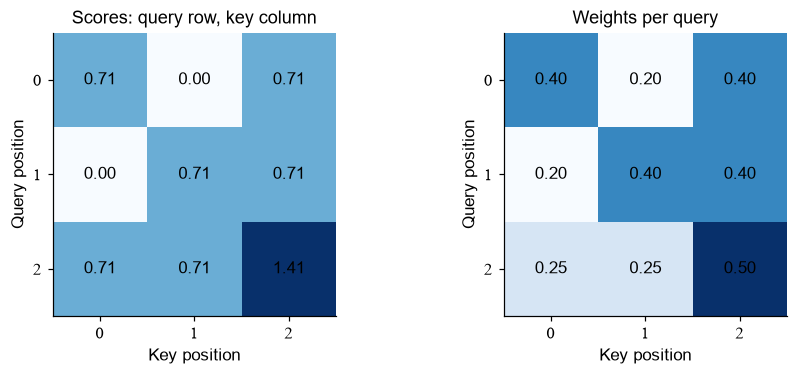

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(8.2, 3.3), layout='constrained')
for ax, matrix, title in zip(axes, [table,A], ['Scores: query row, key column','Weights per query']):
    im = ax.imshow(matrix.detach(), cmap='Blues')
    for i in range(3):
        for j in range(3):
            ax.text(j,i,f'{matrix[i,j]:.2f}',ha='center',va='center',color='black')
    ax.set(xticks=range(3),yticks=range(3),xlabel='Key position',ylabel='Query position',title=title)
show(fig)

### 练习 a02：判断 Softmax 的轴

自己计算 Q 对全部 K 的分数表，并让每个查询对应一行概率。

In [9]:
ex_a02_scores = None
ex_a02_A = None

In [10]:
# 填写上一格后，运行检查。
check('分数表',ex_a02_scores,table)
check('权重',ex_a02_A,A)

待填写：分数表
待填写：权重


<details>
<summary>提示</summary>

Q @ K.T 后，最后一轴枚举可读的位置。

</details>

<details>
<summary>参考答案</summary>

```python
ex_a02_scores = Q @ K.T / np.sqrt(2)
ex_a02_A = torch.softmax(ex_a02_scores,dim=-1)
```

</details>

## 3 缩放因子从哪里来

若 q、k 的各分量独立、均值为 0、方差为 1，则乘积每项方差为 1，d 项相加的方差为 d。除以 $\sqrt d$ 后方差回到 1。这个估计解释缩放的出发点；实际训练得到的分量有自己的相关性。

维数增加时，未缩放的点积波动变大；Softmax 可能因此把比例分得很悬殊。下面将 d 从4增加到64，用实际标准差观察这件事。缩放控制的是进入 Softmax 的分数尺度。

In [11]:
torch.manual_seed(3)
for d in [4,64]:
    random_q, random_k = torch.randn(2000,d), torch.randn(2000,d)
    dots = (random_q*random_k).sum(dim=-1)
    print('d=',d,'点积std=',round(dots.std().item(),2),
          '缩放后std=',round((dots/d**.5).std().item(),2))

d= 4 点积std= 2.1 缩放后std= 1.05
d= 64 点积std= 8.03 缩放后std= 1.0


## 4 预测下一个字符时，只读取当前位置及过去

生成一句话时，后面的字符尚未出现。训练时虽然整句已经在文件里，模型也应练习从已有前文作预测；否则它可以直接读取要预测的答案。

位置 i 预测第 i+1 个字符，于是只允许读取 $j\le i$。用 $-\infty$ 替换未来位置的分数，Softmax 中对应的指数就为零。下面的下三角表把“此刻可读到哪里”逐行画了出来。

In [12]:
allowed = torch.tril(torch.ones(3,3)).bool()
masked_scores = table.masked_fill(~allowed,float('-inf'))
causal_A = torch.softmax(masked_scores,dim=-1)
print('允许读取的位置：\n',allowed)
print('加mask后的权重：\n',causal_A)
check('未来位置权重为0',causal_A[~allowed],torch.zeros(3))

允许读取的位置：
 tensor([[ True, False, False],
        [ True,  True, False],
        [ True,  True,  True]])
加mask后的权重：
 tensor([[1.0000, 0.0000, 0.0000],
        [0.3302, 0.6698, 0.0000],
        [0.2483, 0.2483, 0.5035]])
通过：未来位置权重为0


### 练习 a03：亲手制作因果掩码

制作长度为 4 的因果掩码，保留对角线。

In [13]:
ex_a03_mask = None

In [14]:
# 填写上一格后，运行检查。
check('4位置掩码',ex_a03_mask,np.tril(np.ones((4,4))).astype(bool))

待填写：4位置掩码


<details>
<summary>提示</summary>

`torch.tril` 保留主对角线及下方，再转 bool。

</details>

<details>
<summary>参考答案</summary>

```python
ex_a03_mask = torch.tril(torch.ones(4,4)).bool()
```

</details>

## 5 Q、K、V 都由同一个输入投影出来

目前查询、键和值是分别填写的数组。实际网络收到的是同一份输入 X：每行代表一个位置。对它做三种可训练的线性变换，便得到 $Q=XW_Q$、$K=XW_K$、$V=XW_V$。三份权重让同一份原始特征分别承担查询、匹配与传递内容的工作。

下面把这几行接成函数，再改变最后一个输入位置。前两个输出保持相同，说明它们确实没有读取后来发生的变化。

In [15]:
torch.manual_seed(5)
Wq,Wk,Wv = [torch.randn(2,2) for _ in range(3)]
def causal_read(X):
    q,k,v = X@Wq, X@Wk, X@Wv
    scores = (q@k.T)/np.sqrt(2)
    mask = torch.tril(torch.ones(len(X),len(X))).bool()
    return torch.softmax(scores.masked_fill(~mask,float('-inf')),dim=-1)@v
X = torch.tensor([[1.,0.],[0.,1.],[1.,1.]])
print(causal_read(X))

tensor([[ 0.6312, -0.8991],
        [ 0.2630, -0.4068],
        [-0.0632,  0.0038]])

In [16]:
changed = X.clone()
changed[-1] += torch.tensor([4.,-3.])
check('未来输入改变，早期输出相同',causal_read(changed)[:2],causal_read(X)[:2])

通过：未来输入改变，早期输出相同


### 练习 a04：写一次查询输出

只算第 1 个位置，它可以读取位置 0 和 1。用相应两行 K、V 计算。

In [17]:
ex_a04_answer = None

In [18]:
# 填写上一格后，运行检查。
check('第1位置的输出',ex_a04_answer,(causal_A@V)[1])

待填写：第1位置的输出


<details>
<summary>提示</summary>

先做 Q[1] @ K[:2].T，Softmax，再乘 V[:2]。

</details>

<details>
<summary>参考答案</summary>

```python
ex_a04_answer = torch.softmax(Q[1]@K[:2].T/np.sqrt(2),dim=-1)@V[:2]
```

</details>

## 6 反向梯度同时经过三条投影路径

三份投影来自同一个 X。改变 X 的一个元素，会同时改变它提出的查询、供别人匹配的键和被别人取走的值。回传到这个元素的梯度，因而需要收齐三条路的贡献。

沿用上一节的具体数值，把这段依赖展开：
$$X\longrightarrow(Q,K,V)\longrightarrow S=QK^\top/\sqrt d
\longrightarrow A=\operatorname{softmax}_{\rm row}(\operatorname{mask}(S))
\longrightarrow Y=AV\longrightarrow L.$$

记 $D_Z=\partial L/\partial Z$，它与 Z 的形状相同。对本例，X、Q、K、V、Y 都为 3×2，S、A 为 3×3，$d=2$。
先为数值核对新建 float64 的输入和权重副本，并让三份权重也参与求导。

In [19]:
backward_X = X.detach().double().clone().requires_grad_()
backward_Wq, backward_Wk, backward_Wv = [
    weight.detach().double().clone().requires_grad_() for weight in (Wq, Wk, Wv)]
backward_q = backward_X @ backward_Wq
backward_k = backward_X @ backward_Wk
backward_v = backward_X @ backward_Wv
backward_scale = backward_q.shape[-1] ** .5

先重现正向的每个中间量。`retain_grad()` 让反传后可以读取这些中间节点收到的梯度，逐步与手算结果比较。

In [20]:
backward_allowed = torch.tril(torch.ones(len(X), len(X))).bool()
backward_scores = backward_q @ backward_k.T / backward_scale
backward_A = torch.softmax(backward_scores.masked_fill(~backward_allowed, float('-inf')), dim=-1)
backward_Y = backward_A @ backward_v
for intermediate in (backward_q, backward_k, backward_v, backward_scores, backward_A, backward_Y):
    intermediate.retain_grad()
print('因果权重 A：\n', backward_A.detach(), '\n输出 Y：\n', backward_Y.detach())

因果权重 A：


 tensor([[1.0000, 0.0000, 0.0000],
        [0.6903, 0.3097, 0.0000],
        [0.1702, 0.3667, 0.4631]], dtype=torch.float64) 
输出 Y：
 tensor([[ 0.6312, -0.8991],
        [ 0.2630, -0.4068],
        [-0.0632,  0.0038]], dtype=torch.float64)


### 6.1 从输出梯度拆开 Y=AV

这里取 $L=\sum_{i,r}Y_{ir}$，所以输出收到的梯度 $G=D_Y$ 每项都是 1。
由 $Y_{ir}=\sum_jA_{ij}V_{jr}$ 得
$$D_V=A^\top G\quad(3\times2),\qquad D_A=GV^\top\quad(3\times3).$$
一个值向量被多个查询读取，$D_V$ 沿这些查询累加；一个权重影响输出向量的所有坐标，$D_A$ 沿特征坐标累加。
下面取出正向数值，显式写出反向计算。

In [21]:
backward_Q_value, backward_K_value, backward_V_value = [
    value.detach() for value in (backward_q, backward_k, backward_v)]
backward_A_value = backward_A.detach()
backward_G = torch.ones_like(backward_Y)
backward_dV = backward_A_value.T @ backward_G
backward_dA = backward_G @ backward_V_value.T
print('输出梯度 G：\n', backward_G)
print('D_V：\n', backward_dV, '\nD_A：\n', backward_dA)

输出梯度 G：
 

tensor([[1., 1.],
        [1., 1.],
        [1., 1.]], dtype=torch.float64)
D_V：
 tensor([[1.8605, 1.8605],
        [0.6764, 0.6764],
        [0.4631, 0.4631]], dtype=torch.float64) 
D_A：
 tensor([[-0.2679,  0.1329, -0.1350],
        [-0.2679,  0.1329, -0.1350],
        [-0.2679,  0.1329, -0.1350]], dtype=torch.float64)


### 6.2 把整行 Softmax 的偏导收集起来

同一查询行内，$\partial A_{ij}/\partial S_{im}=A_{ij}(\delta_{jm}-A_{im})$，
其中 $\delta_{jm}$ 在 j=m 时为 1，否则为 0。应用链式法则并整理求和：
$$D_{S,ij}=\sum_m D_{A,im}\frac{\partial A_{im}}{\partial S_{ij}}
=A_{ij}\left(D_{A,ij}-\sum_m A_{im}D_{A,im}\right).$$
这就是行 Softmax 的反向向量乘积：先算每行的概率加权平均，再逐项相减、乘概率。
mask 把未来位置替换成常数，因此这些位置对原分数 S 的导数为 0。

In [22]:
backward_row_average = (backward_A_value * backward_dA).sum(dim=-1, keepdim=True)
backward_dS = backward_A_value * (backward_dA - backward_row_average)
backward_dS = backward_dS.masked_fill(~backward_allowed, 0.)
print('各行加权平均：\n', backward_row_average, '\nD_S：\n', backward_dS)
check('mask位置不传梯度', backward_dS[~backward_allowed], torch.zeros(3, dtype=torch.float64))
check('每行分数梯度和为0', backward_dS.sum(dim=-1), torch.zeros(3, dtype=torch.float64))

各行加权平均：
 tensor([[-0.2679],
        [-0.1438],
        [-0.0594]], dtype=torch.float64) 
D_S：
 tensor([[ 0.0000,  0.0000,  0.0000],
        [-0.0857,  0.0857,  0.0000],
        [-0.0355,  0.0705, -0.0350]], dtype=torch.float64)
通过：mask位置不传梯度
通过：每行分数梯度和为0


### 6.3 从匹配分数回到查询与键

$S_{ij}=\sum_rQ_{ir}K_{jr}/\sqrt d$，所以局部导数分别为
$\partial S_{ij}/\partial Q_{ir}=K_{jr}/\sqrt d$、
$\partial S_{ij}/\partial K_{jr}=Q_{ir}/\sqrt d$。
把查询行、键列收到的贡献分别相加：
$$D_Q=D_SK/\sqrt d,\qquad D_K=D_S^\top Q/\sqrt d.$$
查询梯度收集该查询对所有键的匹配变化，键梯度收集所有查询对该键的匹配变化。

In [23]:
backward_dQ = backward_dS @ backward_K_value / backward_scale
backward_dK = backward_dS.T @ backward_Q_value / backward_scale
print('D_Q：\n', backward_dQ)
print('D_K：\n', backward_dK)

D_Q：
 tensor([[ 0.0000,  0.0000],
        [-0.0730, -0.1639],
        [-0.0253, -0.1160]], dtype=torch.float64)
D_K：
 tensor([[ 0.0600, -0.0420],
        [-0.0859,  0.0436],
        [ 0.0259, -0.0016]], dtype=torch.float64)


### 6.4 三条投影路径在输入处汇合

对于行向量约定的 $Q=XW_Q$，有 $D_X^{(Q)}=D_QW_Q^\top$；另外两条路径同理。
输入 X 在图中被使用三次，所以必须把三份梯度相加：
$$D_X=D_QW_Q^\top+D_KW_K^\top+D_VW_V^\top.$$
打印三张 3×2 表，分别观察查询、键、值路径给每个输入元素的贡献。

In [24]:
backward_dX_q = backward_dQ @ backward_Wq.detach().T
backward_dX_k = backward_dK @ backward_Wk.detach().T
backward_dX_v = backward_dV @ backward_Wv.detach().T
backward_dX = backward_dX_q + backward_dX_k + backward_dX_v
for name, contribution in [('Q路径', backward_dX_q), ('K路径', backward_dX_k), ('V路径', backward_dX_v)]:
    print(name, '\n', contribution)
print('汇合后的输入梯度：\n', backward_dX)

Q路径 
 tensor([[ 0.0000,  0.0000],
        [ 0.1345, -0.0687],
        [ 0.0824, -0.0633]], dtype=torch.float64)
K路径 
 tensor([[-0.0935, -0.0521],
        [ 0.1017,  0.0872],
        [-0.0082, -0.0351]], dtype=torch.float64)
V路径 
 tensor([[-0.4985,  0.2473],
        [-0.1812,  0.0899],
        [-0.1241,  0.0616]], dtype=torch.float64)
汇合后的输入梯度：
 tensor([[-0.5920,  0.1952],
        [ 0.0550,  0.1084],
        [-0.0499, -0.0368]], dtype=torch.float64)


横轴为输入特征，纵轴为序列位置。四张图使用同一颜色尺度；在同一位置、同一特征处，Q、K、V 三张图的数值相加，得到总梯度图的对应格。

位置0只能读取自己，只有一个分数的 Softmax 恒为1，因此该位置的 Q 路径梯度为0。它的 K 还会被后续位置查询，所以 K 路径可以有非零梯度。

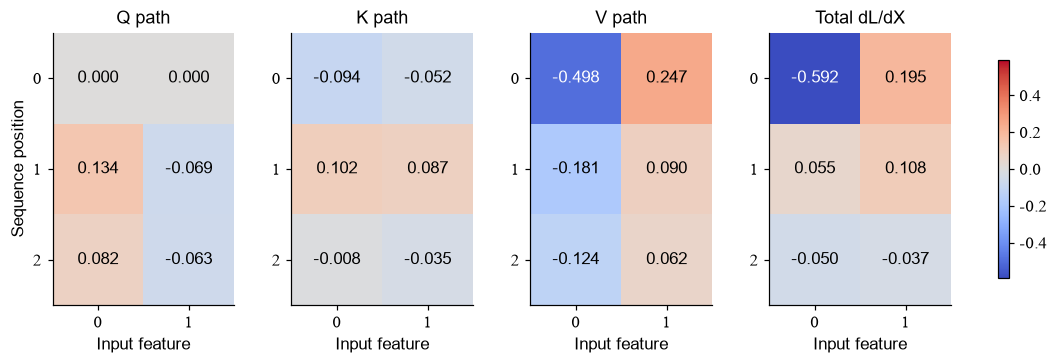

In [25]:
parts = [backward_dX_q, backward_dX_k, backward_dX_v, backward_dX]
limit = max(part.abs().max().item() for part in parts)
fig, axes = plt.subplots(1, 4, figsize=(9.8, 3.2), layout='constrained')
for ax, part, title in zip(axes, parts, ['Q path', 'K path', 'V path', 'Total dL/dX']):
    heat = ax.imshow(part, cmap='coolwarm', vmin=-limit, vmax=limit)
    for row, col in np.ndindex(tuple(part.shape)):
        ax.text(col, row, f'{part[row,col]:.3f}', ha='center', va='center', fontsize=11,
                color='white' if abs(part[row,col].item()) > .6 * limit else 'black')
    ax.set(xticks=[0,1], yticks=[0,1,2], xlabel='Input feature', title=title)
axes[0].set_ylabel('Sequence position'); fig.colorbar(heat, ax=list(axes), shrink=.8)
show(fig)

每份投影权重也收到梯度。一个权重被三个输入位置共用，因此沿位置求和：
$$D_{W_Q}=X^\top D_Q,\qquad D_{W_K}=X^\top D_K,\qquad D_{W_V}=X^\top D_V.$$
这三份矩阵才是优化器更新投影参数时使用的量。

In [26]:
backward_dWq = backward_X.detach().T @ backward_dQ
backward_dWk = backward_X.detach().T @ backward_dK
backward_dWv = backward_X.detach().T @ backward_dV
for name, gradient in [('W_Q', backward_dWq), ('W_K', backward_dWk), ('W_V', backward_dWv)]:
    print(name, '的梯度：\n', gradient)

W_Q 的梯度：
 tensor([[-0.0253, -0.1160],
        [-0.0983, -0.2799]], dtype=torch.float64)
W_K 的梯度：
 tensor([[ 0.0859, -0.0436],
        [-0.0600,  0.0420]], dtype=torch.float64)
W_V 的梯度：
 tensor([[2.3236, 2.3236],
        [1.1395, 1.1395]], dtype=torch.float64)


### 6.5 逐个中间量与 autograd 核对

现在才对同一正向图调用 `backward()`。不仅比较最终输入梯度，也检查输出乘法、Softmax、匹配分数和三条投影的每一步。

In [27]:
backward_Y.sum().backward()
for name, manual, automatic in [
    ('G', backward_G, backward_Y.grad), ('D_V', backward_dV, backward_v.grad),
    ('D_A', backward_dA, backward_A.grad), ('D_S', backward_dS, backward_scores.grad),
    ('D_Q', backward_dQ, backward_q.grad), ('D_K', backward_dK, backward_k.grad)]:
    check(name + '逐步反传', manual, automatic, atol=1e-9)

通过：G逐步反传
通过：D_V逐步反传
通过：D_A逐步反传
通过：D_S逐步反传
通过：D_Q逐步反传
通过：D_K逐步反传


In [28]:
check('三路径输入梯度之和', backward_dX, backward_X.grad, atol=1e-9)
check('查询投影权重梯度', backward_dWq, backward_Wq.grad, atol=1e-9)
check('键投影权重梯度', backward_dWk, backward_Wk.grad, atol=1e-9)
check('值投影权重梯度', backward_dWv, backward_Wv.grad, atol=1e-9)

通过：三路径输入梯度之和
通过：查询投影权重梯度
通过：键投影权重梯度
通过：值投影权重梯度


### 6.6 再用一次正向扰动核对输入偏导

中心差分只改变 X[1,0]，比较损失在 $+\varepsilon$、$-\varepsilon$ 两个输入处的差。
函数使用本节的 float64 权重数值重新计算正向，与沿计算图逐边传播的结果比较。

In [29]:
def backward_forward(input_value):
    q_value = input_value @ backward_Wq.detach()
    k_value = input_value @ backward_Wk.detach()
    v_value = input_value @ backward_Wv.detach()
    score_value = q_value @ k_value.T / backward_scale
    a_value = torch.softmax(score_value.masked_fill(~backward_allowed, float('-inf')), dim=-1)
    return a_value @ v_value

In [30]:
eps = 1e-5
plus,minus = backward_X.detach().clone(),backward_X.detach().clone()
plus[1,0] += eps; minus[1,0] -= eps
finite_difference = (backward_forward(plus).sum()-backward_forward(minus).sum())/(2*eps)
print('输入X[1,0]：手写', backward_dX[1,0].item(), '差分', finite_difference.item())
check('输入偏导差分核对', backward_dX[1,0], finite_difference, atol=1e-7)

输入X[1,0]：手写 0.05499127910656565 差分 0.05499127908037415
通过：输入偏导差分核对


### 练习 a05：Softmax 的非对角导数

权重 `[0.2,0.3,0.5]` 中，求第 0 个概率对第 1 个分数的导数。

In [31]:
ex_a05_derivative = None

In [32]:
# 填写上一格后，运行检查。
check('交叉偏导',ex_a05_derivative,-.06)

待填写：交叉偏导


<details>
<summary>提示</summary>

i≠j 时 δij=0，所以结果是 -p_i*p_j。

</details>

<details>
<summary>参考答案</summary>

```python
ex_a05_derivative = -.2*.3
```

</details>

### 练习 a06：从空函数写出一次因果注意力

输入 q,k,v 已经是按行排列的二维表，完整写出分数、掩码、Softmax、加权和。

In [33]:
def ex_a06_attention(q,k,v):
    return None

In [34]:
# 填写上一格后，运行检查。
check('整段因果输出',ex_a06_attention(Q,K,V),causal_A@V)

待填写：整段因果输出


<details>
<summary>提示</summary>

形状依次为 T×d、T×T、T×T、T×dv。

</details>

<details>
<summary>参考答案</summary>

```python
def ex_a06_attention(q,k,v):
    scores=q@k.T/q.shape[-1]**.5
    mask=torch.tril(torch.ones(len(q),len(k))).bool()
    return torch.softmax(scores.masked_fill(~mask,float('-inf')),dim=-1)@v
```

</details>

## 带着问题读原文

[Attention Is All You Need §3.2](https://arxiv.org/abs/1706.03762)

在论文公式中找出 Q、K、V、缩放、Softmax 对应的五行代码。独立实验：保持输入和投影相同，只移除 mask，再改变最后一个位置，测量第 0 个位置输出的变化。